In [1]:
# Import libraries for exploratory data analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3

print("EDA libraries imported successfully!")

EDA libraries imported successfully!


In [1]:

import pandas as pd

transactions = pd.read_csv("https://raw.githubusercontent.com/naisoisharonkarinoh/plp-capstone-retail-sharon-koina/main/data/transactions.csv")
products = pd.read_csv("https://raw.githubusercontent.com/naisoisharonkarinoh/plp-capstone-retail-sharon-koina/main/data/products.csv")
branches = pd.read_csv("https://raw.githubusercontent.com/naisoisharonkarinoh/plp-capstone-retail-sharon-koina/main/data/branches.csv")
customers = pd.read_csv("https://raw.githubusercontent.com/naisoisharonkarinoh/plp-capstone-retail-sharon-koina/main/data/customers.csv")

print("All four CSV files loaded successfully!")
print("Transactions:", transactions.shape)
print("Products:", products.shape)
print("Branches:", branches.shape)
print("Customers:", customers.shape)


All four CSV files loaded successfully!
Transactions: (50000, 8)
Products: (20, 4)
Branches: (5, 2)
Customers: (5000, 2)


In [3]:
# Calculate key supermarket sales metrics

# Calculate sales amount for each transaction
transactions["sales_amount"] = (
    transactions["quantity"] * transactions["unit_price"]
)

# Calculate the key performance indicators
total_revenue = transactions["sales_amount"].sum()
total_transactions = transactions["transaction_id"].nunique()
total_units_sold = transactions["quantity"].sum()
average_transaction_value = (
    total_revenue / total_transactions
)

# Display the results
print("SUPERMARKET SALES SCORECARD")
print("---------------------------")
print(f"Total Revenue: KES {total_revenue:,.2f}")
print(f"Total Transactions: {total_transactions:,}")
print(f"Total Units Sold: {total_units_sold:,}")
print(
    f"Average Transaction Value: "
    f"KES {average_transaction_value:,.2f}"
)

SUPERMARKET SALES SCORECARD
---------------------------
Total Revenue: KES 38,292,565.00
Total Transactions: 50,000
Total Units Sold: 274,143
Average Transaction Value: KES 765.85


In [4]:
# Analyse sales performance by product

product_sales = transactions.merge(
    products,
    on="product_id",
    how="left"
)

product_performance = (
    product_sales
    .groupby("product_name")
    .agg(
        total_revenue=("sales_amount", "sum"),
        units_sold=("quantity", "sum"),
        transaction_count=("transaction_id", "nunique")
    )
    .sort_values("total_revenue", ascending=False)
)

print("TOP 10 PRODUCTS BY REVENUE")

display(
    product_performance.head(10).round(2)
)

TOP 10 PRODUCTS BY REVENUE


,total_revenue,units_sold,transaction_count
product_name,,,
Cooking Oil,4650450,13287,2438
Coffee,4168200,13894,2500
Detergent,3440000,13760,2524
Cereal,2964720,13476,2484
Rice,2488680,13826,2564
Beans,2356880,13864,2548
Sugar,2121440,13259,2482
Wheat Flour,2113200,14088,2516
Toothpaste,2080800,13872,2514


In [5]:
# Analyse sales performance by branch

branch_sales = transactions.merge(
    branches,
    on="branch_id",
    how="left"
)

branch_performance = (
    branch_sales
    .groupby("branch_name")
    .agg(
        total_revenue=("sales_amount", "sum"),
        total_transactions=("transaction_id", "nunique"),
        units_sold=("quantity", "sum")
    )
    .sort_values("total_revenue", ascending=False)
)

print("SALES PERFORMANCE BY BRANCH")

display(branch_performance.round(2))

SALES PERFORMANCE BY BRANCH


,total_revenue,total_transactions,units_sold
branch_name,,,
Kisumu,7756715,10102,55687
Nakuru,7687115,9964,54811
Mombasa,7669890,10025,54814
Nairobi,7637720,9947,54317
Eldoret,7541125,9962,54514


In [6]:
# Analyse monthly supermarket sales

transactions["month"] = (
    transactions["date"].dt.to_period("M")
)

monthly_sales = (
    transactions.groupby("month")
    .agg(
        total_revenue=("sales_amount", "sum"),
        total_transactions=("transaction_id", "nunique")
    )
    .reset_index()
)

monthly_sales["month"] = (
    monthly_sales["month"].astype(str)
)

print("MONTHLY SALES PERFORMANCE")
display(monthly_sales.round(2))

MONTHLY SALES PERFORMANCE


,month,total_revenue,total_transactions
0,2025-01,3406405,4396
1,2025-02,2965845,3814
2,2025-03,3293075,4342
3,2025-04,3142480,4110
4,2025-05,3209885,4188
5,2025-06,3033615,4007
6,2025-07,3149030,4133
7,2025-08,3296470,4308
8,2025-09,3263335,4169
9,2025-10,3193165,4240


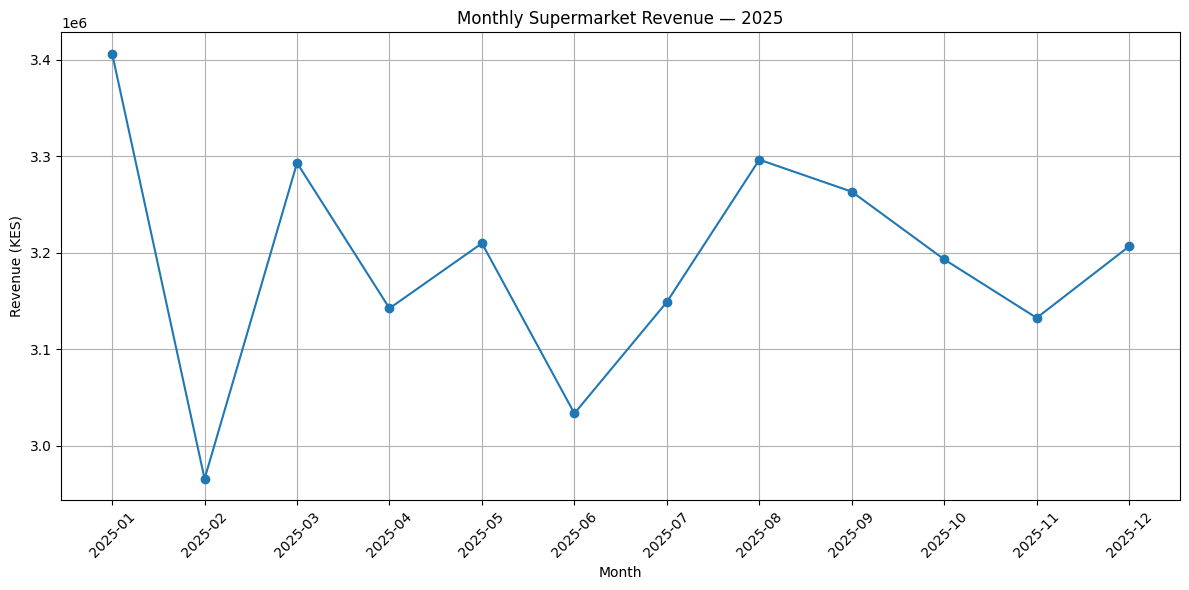

In [7]:
# Visualise monthly sales revenue

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales["month"],
    monthly_sales["total_revenue"],
    marker="o"
)

plt.title("Monthly Supermarket Revenue — 2025")
plt.xlabel("Month")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

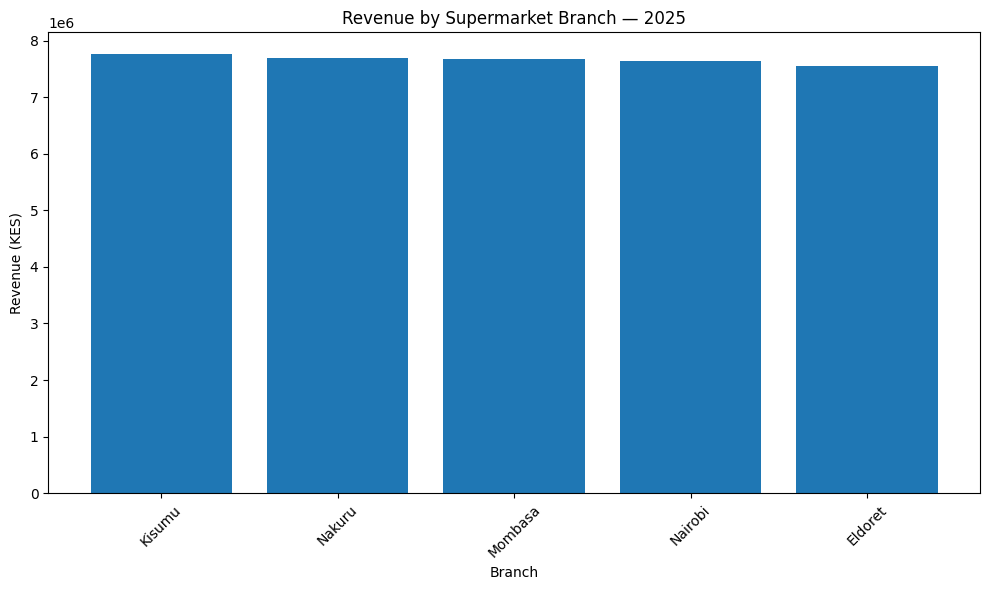

In [8]:
# Visualise revenue by supermarket branch

plt.figure(figsize=(10, 6))

plt.bar(
    branch_performance.index,
    branch_performance["total_revenue"]
)

plt.title("Revenue by Supermarket Branch — 2025")
plt.xlabel("Branch")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [9]:
# Analyse sales by customer segment

customer_sales = transactions.merge(
    customers,
    on="customer_id",
    how="left"
)

customer_performance = (
    customer_sales
    .groupby("customer_segment")
    .agg(
        total_revenue=("sales_amount", "sum"),
        total_transactions=("transaction_id", "nunique"),
        unique_customers=("customer_id", "nunique"),
        units_sold=("quantity", "sum")
    )
    .sort_values("total_revenue", ascending=False)
)

print("CUSTOMER SEGMENT PERFORMANCE")

display(customer_performance.round(2))

CUSTOMER SEGMENT PERFORMANCE


,total_revenue,total_transactions,unique_customers,units_sold
customer_segment,,,,
Regular,19096510,24995,2499,137303
Occasional,13481160,17648,1770,96127
Premium,5714895,7357,730,40713


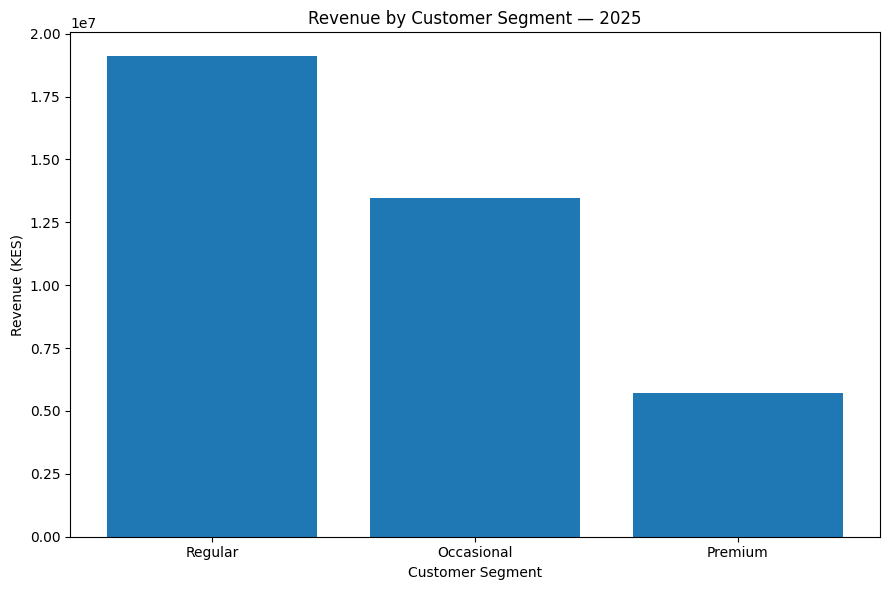

In [10]:
# Visualise revenue by customer segment

plt.figure(figsize=(9, 6))

plt.bar(
    customer_performance.index,
    customer_performance["total_revenue"]
)

plt.title("Revenue by Customer Segment — 2025")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue (KES)")
plt.tight_layout()

plt.show()

In [11]:
# Analyse sales by product category

category_sales = transactions.merge(
    products[["product_id", "category", "product_name"]],
    on="product_id",
    how="left"
)

category_performance = (
    category_sales
    .groupby("category")
    .agg(
        total_revenue=("sales_amount", "sum"),
        units_sold=("quantity", "sum"),
        total_transactions=("transaction_id", "nunique")
    )
    .sort_values("total_revenue", ascending=False)
)

print("REVENUE BY PRODUCT CATEGORY")

display(category_performance.round(2))

REVENUE BY PRODUCT CATEGORY


,total_revenue,units_sold,total_transactions
category,,,
Groceries,17705830,109130,19975
Beverages,7839340,55013,9961
Household,4828200,27642,5047
Breakfast,2964720,13476,2484
Personal Care,2080800,13872,2514
Dairy,1311605,27797,5023
Bakery,872820,13428,2450
Snacks,689250,13785,2546
